# Atelier jour 3 : sécurité, analyse et visualisation

TP3 BigData Commerce Analytics (B2 Sup de Vinci).

Ce notebook reprend les collections MongoDB remplies au TP2 (`raw_commandes` et `raw_payments`), pseudonymise les identifiants clients avec HMAC, exporte des datasets analytiques en Parquet, puis construit les trois graphiques demandés. La collecte et l'ingestion ne sont pas refaites : il faut que `TP2_Atelier_1_ingestion_api_mongodb.ipynb` ait été exécuté.

## Imports

- `os` pour lire la clé secrète dans les variables d'environnement, `hmac` et `hashlib` pour la pseudonymisation ;
- `pandas` pour manipuler les données, `matplotlib` pour les graphiques ;
- `MongoClient` pour lire les collections MongoDB.

In [29]:
import hashlib
import hmac
import os
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
from pymongo import MongoClient

# Partie 1 : sécurité et confidentialité

## Atelier 1 : pseudonymiser les identifiants clients

### 1. Récupérer la clé secrète

La clé n'est jamais écrite dans le notebook : on la lit dans la variable d'environnement `PSEUDO_KEY`, définie avant de lancer Jupyter. Sous Windows avec VS Code, on l'a définie une fois pour toutes avec `setx PSEUDO_KEY "..."` dans un terminal, puis on a redémarré VS Code pour que le kernel la voie.

Dans le code : si la variable est absente, on arrête le notebook avec un message clair au lieu de continuer avec une clé vide. On affiche seulement la longueur de la clé pour vérifier qu'elle est chargée, jamais la clé elle-même.

In [30]:
PSEUDO_KEY = os.environ.get("PSEUDO_KEY")

if not PSEUDO_KEY:
    raise ValueError(
        "La variable d'environnement PSEUDO_KEY n'est pas définie. "
        "Dans un terminal : setx PSEUDO_KEY \"votre-cle\", puis redémarrer VS Code."
    )

print("Clé chargée :", len(PSEUDO_KEY), "caractères")

Clé chargée : 24 caractères


### 2. Fonction de pseudonymisation

HMAC-SHA256 calcule une empreinte à partir de l'identifiant **et** de la clé secrète. Le même identifiant avec la même clé donne toujours le même pseudonyme, mais sans la clé on ne peut ni retrouver l'identifiant, ni recalculer le pseudonyme d'un client donné.

Dans le code :
- l'identifiant est converti en texte puis en octets (`encode("utf-8")`), comme la clé ;
- `hmac.new(cle, message, hashlib.sha256)` calcule l'empreinte, `hexdigest()` la donne en hexadécimal (64 caractères) ;
- on garde les 16 premiers caractères pour avoir un pseudonyme plus lisible. Avec 208 clients, le risque que deux clients tombent sur le même pseudonyme est négligeable, et on le vérifie plus bas.

In [31]:
def pseudonymiser(valeur):
    message = str(valeur).encode("utf-8")
    empreinte = hmac.new(PSEUDO_KEY.encode("utf-8"), message, hashlib.sha256)
    return empreinte.hexdigest()[:16]

### 3. Charger les données depuis MongoDB

Dans le code :
- `find({}, {"_id": 0})` lit tous les documents sans le champ technique `_id`, et `pd.DataFrame(list(...))` les place dans un DataFrame ;
- dans notre collection, le statut de paiement s'appelle `status` ; on le renomme `payment_status` pour reprendre le vocabulaire du TP.

In [32]:
client = MongoClient("mongodb://localhost:27017", serverSelectionTimeoutMS=3000)
db = client["commerce"]

df_commandes = pd.DataFrame(list(db.raw_commandes.find({}, {"_id": 0})))
df_paiements = pd.DataFrame(list(db.raw_payments.find({}, {"_id": 0})))
df_paiements = df_paiements.rename(columns={"status": "payment_status"})

print("Commandes :", df_commandes.shape)
print("Paiements :", df_paiements.shape)

Commandes : (800, 16)
Paiements : (208, 10)


### 4. Préparer les données

Avant de calculer quoi que ce soit, on s'assure que les montants sont bien des nombres et les dates de vraies dates.

Dans le code :
- `pd.to_numeric(..., errors="coerce")` convertit en nombre et remplace par NaN ce qui ne peut pas être converti ;
- `pd.to_datetime(..., errors="coerce")` fait la même chose pour les dates (NaT si la date est invalide) ;
- on compte les valeurs invalides, puis on écarte les lignes concernées. Sur nos données il n'y en a aucune, mais le contrôle reste utile si les sources changent.

In [33]:
for col in ["quantity", "unit_price", "line_total", "discounted_line_total"]:
    df_commandes[col] = pd.to_numeric(df_commandes[col], errors="coerce")
df_commandes["order_date"] = pd.to_datetime(df_commandes["order_date"], errors="coerce")

for col in ["amount", "amount_collected"]:
    df_paiements[col] = pd.to_numeric(df_paiements[col], errors="coerce")
df_paiements["payment_date"] = pd.to_datetime(df_paiements["payment_date"], errors="coerce")

invalides_commandes = df_commandes[["discounted_line_total", "order_date"]].isna().any(axis=1).sum()
invalides_paiements = df_paiements[["amount", "payment_date"]].isna().any(axis=1).sum()
print("Commandes invalides (montant ou date) :", invalides_commandes)
print("Paiements invalides (montant ou date) :", invalides_paiements)

df_commandes = df_commandes.dropna(subset=["discounted_line_total", "order_date"])
df_paiements = df_paiements.dropna(subset=["amount", "payment_date"])
print("Après nettoyage :", len(df_commandes), "commandes,", len(df_paiements), "paiements")

Commandes invalides (montant ou date) : 0
Paiements invalides (montant ou date) : 0
Après nettoyage : 800 commandes, 208 paiements


### 5. Pseudonymiser les commandes

Dans le code : `map(pseudonymiser)` applique la fonction à chaque valeur de `user_id` et crée la colonne `user_id_pseudo`. On affiche ensuite quelques clients avant et après pseudonymisation.

In [34]:
df_commandes["user_id_pseudo"] = df_commandes["user_id"].map(pseudonymiser)

exemples = (
    df_commandes[["user_id", "user_id_pseudo"]]
    .drop_duplicates()
    .sort_values("user_id")
    .head(5)
    .reset_index(drop=True)
)
display(exemples)

,user_id,user_id_pseudo
0,1,7f0a7318676fd0c1
1,2,a7450b576f9ec059
2,3,9636b4edf3e3c07b
3,4,de0f26f4456021dd
4,5,71e2740c82dcb136


### 6. Vérifications

On vérifie trois choses :
- **stabilité** : toutes les lignes d'un même client ont le même pseudonyme (`nunique` du pseudonyme par `user_id` vaut 1) ;
- **pas de collision** : deux clients différents n'ont jamais le même pseudonyme (`nunique` de `user_id` par pseudonyme vaut 1) ;
- **les calculs par client restent possibles** : le montant total par client calculé avec `user_id` est identique à celui calculé avec `user_id_pseudo`.

In [35]:
pseudo_par_client = df_commandes.groupby("user_id")["user_id_pseudo"].nunique()
clients_par_pseudo = df_commandes.groupby("user_id_pseudo")["user_id"].nunique()
print("Clients avec plusieurs pseudonymes :", (pseudo_par_client > 1).sum())
print("Pseudonymes partagés par plusieurs clients :", (clients_par_pseudo > 1).sum())

# Exemple : un client avec plusieurs lignes de commande
client_exemple = df_commandes["user_id"].value_counts().index[0]
print()
print(df_commandes.loc[df_commandes["user_id"] == client_exemple,
                       ["user_id", "user_id_pseudo", "cart_id", "product_title"]].to_string(index=False))

total_par_id = df_commandes.groupby("user_id")["discounted_line_total"].sum().sort_values().round(2).tolist()
total_par_pseudo = df_commandes.groupby("user_id_pseudo")["discounted_line_total"].sum().sort_values().round(2).tolist()
print()
print("Mêmes totaux par client avec user_id et avec user_id_pseudo :", total_par_id == total_par_pseudo)

Clients avec plusieurs pseudonymes : 0
Pseudonymes partagés par plusieurs clients : 0

 user_id   user_id_pseudo  cart_id          product_title
       3 9636b4edf3e3c07b        3             Fish Steak
       3 9636b4edf3e3c07b        3          iPhone 13 Pro
       3 9636b4edf3e3c07b        3               Realme X
       3 9636b4edf3e3c07b        3 Man Short Sleeve Shirt
       3 9636b4edf3e3c07b        3           Dior J'adore
       3 9636b4edf3e3c07b        3          Party Glasses

Mêmes totaux par client avec user_id et avec user_id_pseudo : True


### 7. Pseudonymiser les paiements avec la même clé

On applique la même fonction, avec la même clé, au `user_id` des paiements. Puis on rapproche commandes et paiements par `user_id` pour vérifier que chaque client a bien le même pseudonyme des deux côtés.

In [36]:
df_paiements["user_id_pseudo"] = df_paiements["user_id"].map(pseudonymiser)

correspondance = (
    df_commandes[["user_id", "user_id_pseudo"]].drop_duplicates()
    .merge(df_paiements[["user_id", "user_id_pseudo"]].drop_duplicates(),
           on="user_id", suffixes=("_commandes", "_paiements"))
)
identiques = (correspondance["user_id_pseudo_commandes"] == correspondance["user_id_pseudo_paiements"]).all()
print("Clients rapprochés :", len(correspondance))
print("Même pseudonyme dans les commandes et les paiements :", identiques)
display(correspondance.head(3))

Clients rapprochés : 208
Même pseudonyme dans les commandes et les paiements : True


,user_id,user_id_pseudo_commandes,user_id_pseudo_paiements
0,1,7f0a7318676fd0c1,7f0a7318676fd0c1
1,2,a7450b576f9ec059,a7450b576f9ec059
2,3,9636b4edf3e3c07b,9636b4edf3e3c07b


### Réponses aux questions de l'atelier 1

**1. Identifiants avant et après pseudonymisation.** Voir le tableau de l'étape 5 : chaque `user_id` (1, 2, 3...) est remplacé par une chaîne de 16 caractères hexadécimaux qui ne laisse rien deviner de l'identifiant d'origine.

**2. Pourquoi un même client garde le même pseudonyme.** HMAC est déterministe : le résultat dépend uniquement de l'identifiant et de la clé. Comme on utilise la même clé pour toutes les lignes de commandes et pour les paiements, le même `user_id` donne toujours le même pseudonyme. C'est ce qui permet encore de regrouper les achats d'un client et de relier commandes et paiements, sans manipuler son identifiant réel.

**3. Pourquoi la clé ne doit pas aller sur GitHub ni dans les livrables.** Avec la clé, n'importe qui peut recalculer le pseudonyme de chaque `user_id` possible (il n'y en a que quelques centaines) et donc retrouver à qui correspond chaque pseudonyme : la pseudonymisation ne protège plus rien. Un dépôt GitHub peut être rendu public, copié ou cloné, et une clé poussée une fois reste dans l'historique git même si on la supprime ensuite. C'est pour ça qu'elle est lue dans une variable d'environnement et jamais écrite dans le code.

**4. Limites et précautions.** La pseudonymisation n'est pas une anonymisation : les données restent personnelles au sens du RGPD, car la personne peut être réidentifiée avec la clé, ou par recoupement (un montant de commande précis, une date, une combinaison de produits peuvent suffire à reconnaître quelqu'un). Les datasets générés doivent donc rester protégés : on les garde en local dans `data/analytique/`, exclu de git, on n'y met que les colonnes nécessaires à l'analyse (pas de `user_id`, pas de `username`), on limite qui y a accès, on stocke la clé à part et on la change si elle a pu fuiter. Pour diffuser des résultats plus largement, il vaut mieux publier des agrégats (par catégorie, par mois) plutôt que des lignes par client.

# Partie 2 : analyse et mise en œuvre

## Atelier 2 (1/2) : datasets analytiques en Parquet

On prépare deux datasets pour l'analyse et le dashboard, **sans identifiant direct** :
- on retire `user_id` et `username`, remplacés par `user_id_pseudo` ;
- on retire aussi `cart_total` et `cart_discounted_total` des commandes : ces totaux de panier sont répétés sur chaque ligne et on risquerait de les additionner par erreur.

Les fichiers vont dans `data/analytique/`. Ce dossier est exclu de git (`.gitignore`) : même pseudonymisées, ces données restent à protéger et ne doivent pas se retrouver sur GitHub.

Dans le code : on remonte jusqu'à la racine du projet, on écrit les deux fichiers avec `to_parquet` (bibliothèque `pyarrow`), puis on les relit pour vérifier leur contenu.

In [37]:
racine = Path.cwd()
while racine != racine.parent and not (racine / "data").exists():
    racine = racine.parent
dossier_analytique = racine / "data" / "analytique"
dossier_analytique.mkdir(parents=True, exist_ok=True)

colonnes_commandes = [
    "order_id", "cart_id", "user_id_pseudo", "product_id", "product_title", "category", "brand",
    "quantity", "unit_price", "line_total", "discount_percentage", "discounted_line_total", "order_date",
]
colonnes_paiements = [
    "payment_id", "cart_id", "order_id", "user_id_pseudo", "amount", "payment_status",
    "amount_collected", "payment_date", "nb_lignes", "nb_articles",
]

commandes_analytique = df_commandes[colonnes_commandes]
paiements_analytique = df_paiements[colonnes_paiements]

fichier_commandes = dossier_analytique / "commandes_pseudo.parquet"
fichier_paiements = dossier_analytique / "paiements_pseudo.parquet"
commandes_analytique.to_parquet(fichier_commandes, index=False)
paiements_analytique.to_parquet(fichier_paiements, index=False)

for fichier in [fichier_commandes, fichier_paiements]:
    relu = pd.read_parquet(fichier)
    identifiants = {"user_id", "username"} & set(relu.columns)
    print(f"{fichier.relative_to(racine)} : {relu.shape[0]} lignes, {relu.shape[1]} colonnes, "
          f"identifiants directs présents : {sorted(identifiants) or 'aucun'}, "
          f"clé présente dans le fichier : {PSEUDO_KEY.encode('utf-8') in fichier.read_bytes()}")

data\analytique\commandes_pseudo.parquet : 800 lignes, 13 colonnes, identifiants directs présents : aucun, clé présente dans le fichier : False
data\analytique\paiements_pseudo.parquet : 208 lignes, 10 colonnes, identifiants directs présents : aucun, clé présente dans le fichier : False


## Atelier 2 (2/2) : visualiser les indicateurs

Les trois graphiques sont construits à partir des datasets Parquet pseudonymisés. Chaque graphique est aussi enregistré en PNG dans `resultats/graphiques/` pour la présentation.

Les montants viennent de l'API DummyJSON, qui ne précise pas de devise. On les affiche en euros comme dans le reste du projet, sans conversion : ce sont des valeurs fictives.

In [38]:
commandes = pd.read_parquet(fichier_commandes)
paiements = pd.read_parquet(fichier_paiements)
paiements_paid = paiements[paiements["payment_status"] == "PAID"]

dossier_graphiques = racine / "resultats" / "graphiques"
dossier_graphiques.mkdir(parents=True, exist_ok=True)

format_milliers = mticker.FuncFormatter(lambda x, _: f"{x / 1000:,.0f} k€".replace(",", " "))
print("Paiements PAID :", len(paiements_paid))

Paiements PAID : 150


### Graphique 1 : chiffre d'affaires par catégorie

Règle : somme de `discounted_line_total` par `category` dans les commandes (montant des paniers après remise, payés ou non).

Dans le code : `groupby` + `sum` par catégorie, tri croissant pour que la plus grosse catégorie soit en haut des barres horizontales, puis on écrit la part de chaque catégorie au bout de sa barre.

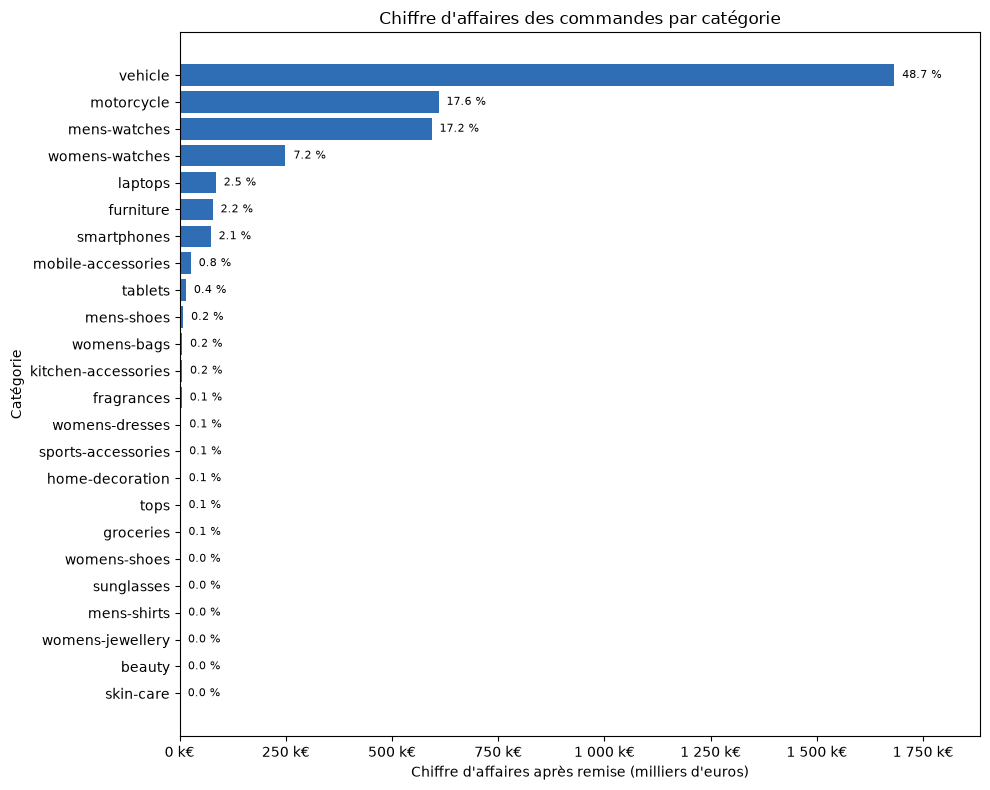

Total : 3 456 709.58 €
category
vehicle           1682064.05
motorcycle         609460.61
mens-watches       593063.86
womens-watches     249189.51


In [39]:
ca_categorie = commandes.groupby("category")["discounted_line_total"].sum().sort_values()
part = ca_categorie / ca_categorie.sum() * 100

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(ca_categorie.index, ca_categorie.values, color="#2f6db5")
for y, (valeur, pct) in enumerate(zip(ca_categorie.values, part.values)):
    ax.text(valeur, y, f"  {pct:.1f} %", va="center", fontsize=8)
ax.set_title("Chiffre d'affaires des commandes par catégorie")
ax.set_xlabel("Chiffre d'affaires après remise (milliers d'euros)")
ax.set_ylabel("Catégorie")
ax.xaxis.set_major_formatter(format_milliers)
ax.set_xlim(0, ca_categorie.max() * 1.12)
fig.tight_layout()
fig.savefig(dossier_graphiques / "01_ca_par_categorie.png", dpi=150)
plt.show()

print(f"Total : {ca_categorie.sum():,.2f} €".replace(",", " "))
print(ca_categorie.sort_values(ascending=False).head(4).round(2).to_string())

**Interprétation.** Le chiffre d'affaires est très concentré : `vehicle` fait à elle seule près de la moitié du total (48,7 %), et les quatre premières catégories (`vehicle`, `motorcycle`, `mens-watches`, `womens-watches`) dépassent 90 %. Les vingt autres catégories se partagent moins de 10 %. Ce classement s'explique surtout par le prix unitaire des produits (un véhicule vaut des dizaines de milliers d'euros, un produit d'épicerie quelques euros) plutôt que par le nombre d'articles vendus. Pour une vraie boutique, ça voudrait dire que l'activité dépend fortement de quelques produits chers : une baisse des ventes de véhicules aurait beaucoup plus d'effet que tout le reste du catalogue.

### Graphique 2 : évolution mensuelle des encaissements

Règle : paiements `PAID` uniquement, somme de `amount` par mois de `payment_date`.

Dans le code : `dt.to_period("M")` ramène chaque date à son mois, on additionne les montants par mois et on compte aussi le nombre de paiements pour l'interprétation.

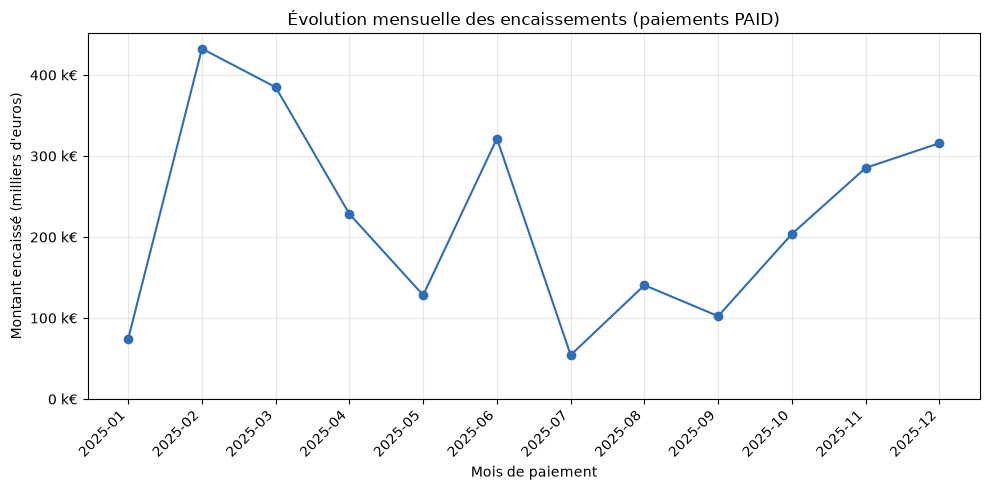

,encaissements,nb_paiements
mois,,
2025-01,74046.27,13
2025-02,432281.84,13
2025-03,384654.44,16
2025-04,228117.54,9
2025-05,128046.30,5
2025-06,321302.66,12
2025-07,54081.45,15
2025-08,140272.22,10
2025-09,102087.86,13


In [40]:
mensuel = (
    paiements_paid
    .assign(mois=paiements_paid["payment_date"].dt.to_period("M"))
    .groupby("mois")
    .agg(encaissements=("amount", "sum"), nb_paiements=("amount", "size"))
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(mensuel.index.astype(str), mensuel["encaissements"], marker="o", color="#2f6db5")
ax.set_title("Évolution mensuelle des encaissements (paiements PAID)")
ax.set_xlabel("Mois de paiement")
ax.set_ylabel("Montant encaissé (milliers d'euros)")
ax.yaxis.set_major_formatter(format_milliers)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
fig.savefig(dossier_graphiques / "02_evolution_mensuelle.png", dpi=150)
plt.show()

display(mensuel.round(2))

**Interprétation.** Les encaissements varient fortement d'un mois à l'autre, de 54 081 € en juillet à 432 282 € en février, alors que le nombre de paiements reste du même ordre (entre 5 et 18 par mois). Les pics ne viennent donc pas d'un plus grand nombre de ventes mais de quelques paniers très chers (véhicules) payés ce mois-là. Il n'y a pas de tendance nette sur l'année. Attention : les dates sont générées pour l'exercice, cette courbe ne montre pas une saisonnalité réelle. Sur de vraies données, on regarderait plutôt le nombre de paiements et le panier moyen, moins sensibles à quelques grosses commandes.

### Graphique 3 : top 10 des clients pseudonymisés

Règle : somme de `amount` des paiements `PAID` par `user_id_pseudo`. Les clients n'apparaissent que sous leur pseudonyme.

Dans le code : `groupby` par pseudonyme, `nlargest(10)` garde les dix plus gros montants, tri croissant pour l'affichage en barres horizontales.

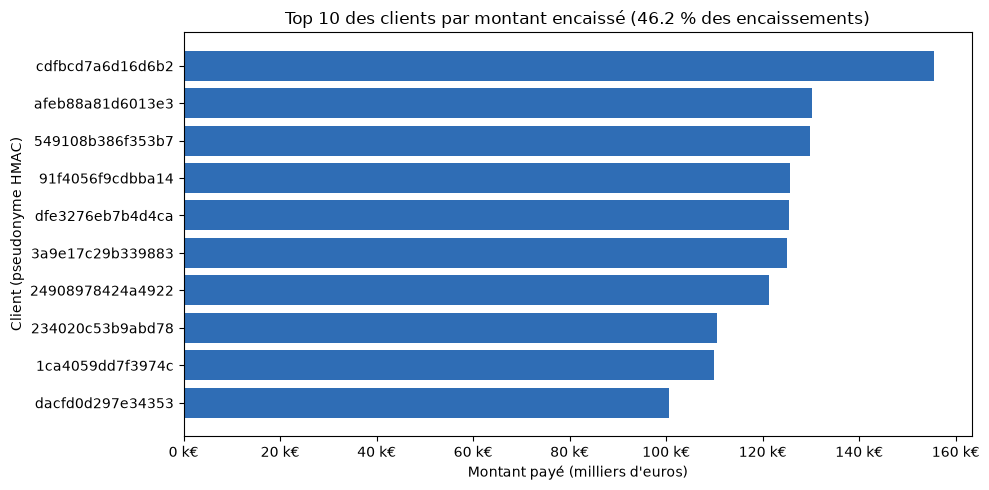

Part du top 10 : 46.2 %
Paniers par client : 1 au maximum


In [41]:
top10 = paiements_paid.groupby("user_id_pseudo")["amount"].sum().nlargest(10).sort_values()
part_top10 = top10.sum() / paiements_paid["amount"].sum() * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top10.index, top10.values, color="#2f6db5")
ax.set_title(f"Top 10 des clients par montant encaissé ({part_top10:.1f} % des encaissements)")
ax.set_xlabel("Montant payé (milliers d'euros)")
ax.set_ylabel("Client (pseudonyme HMAC)")
ax.xaxis.set_major_formatter(format_milliers)
fig.tight_layout()
fig.savefig(dossier_graphiques / "03_top10_clients.png", dpi=150)
plt.show()

print(f"Part du top 10 : {part_top10:.1f} %")
print("Paniers par client :", paiements.groupby("user_id_pseudo").size().max(), "au maximum")

**Interprétation.** Les dix premiers clients représentent 46,2 % des encaissements, alors qu'ils ne sont que 10 sur les 150 clients qui ont payé. Le premier a payé environ 155 500 €. Il faut nuancer : dans les données DummyJSON, chaque client n'a qu'un seul panier, donc ce classement est en fait celui des dix paniers payés les plus chers. On ne peut pas parler de clients fidèles ou réguliers. Le graphique montre aussi l'intérêt de la pseudonymisation : on peut analyser et classer les clients sans afficher leur identifiant.

## Vérification avec les indicateurs du TP2

Les indicateurs du TP2 ont été calculés avec PySpark et exportés dans `resultats/`. On vérifie que pandas retrouve les mêmes valeurs à partir des datasets pseudonymisés.

In [42]:
dossier_tp2 = racine / "resultats"
verifs = []

tp2_categorie = pd.read_csv(dossier_tp2 / "ca_par_categorie.csv").set_index("category")["ca_commande"]
verifs.append(("CA par catégorie", (tp2_categorie.sort_index().round(2) == ca_categorie.sort_index().round(2)).all()))

tp2_mensuel = pd.read_csv(dossier_tp2 / "evolution_mensuelle.csv").set_index("mois")["ca_encaisse"]
tp3_mensuel = mensuel["encaissements"].round(2)
tp3_mensuel.index = tp3_mensuel.index.astype(str)
verifs.append(("Évolution mensuelle", (tp2_mensuel.sort_index().round(2) == tp3_mensuel.sort_index()).all()))

tp2_top10 = sorted(pd.read_csv(dossier_tp2 / "top10_clients.csv")["montant_paye"].round(2))
verifs.append(("Montants du top 10", tp2_top10 == sorted(top10.round(2))))

tp2_statuts = pd.read_csv(dossier_tp2 / "repartition_statuts.csv").set_index("status")["nb_paiements"]
verifs.append(("Répartition des statuts", tp2_statuts.sort_index().tolist() == paiements["payment_status"].value_counts().sort_index().tolist()))

display(pd.DataFrame(verifs, columns=["indicateur", "identique au TP2"]))

,indicateur,identique au TP2
0,CA par catégorie,True
1,Évolution mensuelle,True
2,Montants du top 10,True
3,Répartition des statuts,True


Les valeurs sont identiques : la pseudonymisation ne change aucun résultat, elle remplace seulement l'identifiant affiché. Le top 10 se compare sur les montants, puisque le TP2 affichait les `user_id` et le TP3 les pseudonymes.

## Dashboard

Le dashboard Streamlit se trouve dans `dashboard/app.py` et lit les mêmes fichiers Parquet. Pour le lancer, depuis la racine du projet :

```
python -m streamlit run dashboard/app.py
```